<a href="https://colab.research.google.com/github/lxgcoding/OpenUIE-Benchmark/blob/main/notebooks/00_Quick_Start.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OpenUIE-Benchmark
### An Open-Source Benchmark for Underwater Image Enhancement

Welcome to OpenUIE-Benchmark!

This notebook provides a beginner-friendly entry point for
underwater image enhancement and evaluation.

**Project:** https://github.com/lxgcoding/OpenUIE-Benchmark

**Current development stage:** Initial setup

In [1]:
# ============================================
# 1. Check Python Environment
# ============================================

import sys
import platform

print("=" * 50)
print("OpenUIE-Benchmark Environment")
print("=" * 50)

print("Python version:", sys.version)
print("Platform:", platform.platform())

print("\nEnvironment initialized successfully!")

OpenUIE-Benchmark Environment
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

Environment initialized successfully!


In [2]:
# ============================================
# 2. Check PyTorch and GPU
# ============================================

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected. CPU mode will be used.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
# ============================================
# 3. Mount Google Drive
# ============================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")

In [ ]:
# ============================================
# 4. Create Project Directories
# ============================================

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/OpenUIE-Benchmark"
)

directories = [
    "datasets/UIEB",
    "datasets/LSUI",
    "datasets/EUVP",
    "checkpoints/WaterNet",
    "checkpoints/UWCNN",
    "checkpoints/FUnIE-GAN",
    "inputs",
    "results/UDCP",
    "results/WaterNet",
    "results/metrics",
    "results/comparison",
    "logs"
]

for folder in directories:
    (PROJECT_ROOT / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directories initialized!")
print("Project root:", PROJECT_ROOT)

print("\nDirectory structure:")

for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_dir():
        print("📁", path.relative_to(PROJECT_ROOT))

In [ ]:
# ============================================
# 5. Connect to GitHub Repository
# ============================================

import os
from pathlib import Path

REPO_URL = (
    "https://github.com/lxgcoding/OpenUIE-Benchmark.git"
)

REPO_DIR = Path("/content/OpenUIE-Benchmark")

if REPO_DIR.exists():
    print("Repository already exists.")
    print("Updating repository...")
    !git -C /content/OpenUIE-Benchmark pull
else:
    print("Cloning repository...")
    !git clone {REPO_URL} {REPO_DIR}

print("\nGitHub repository connected!")
print("Repository path:", REPO_DIR)

In [ ]:
# ============================================
# 6. Inspect GitHub Repository
# ============================================

for path in sorted(REPO_DIR.iterdir()):
    print(path.name)

## GitHub Update Test

This section verifies that changes made in Google Colab can be committed back to GitHub.

Project: OpenUIE-Benchmark

In [3]:
import torch
import sys

print("=" * 45)
print("OpenUIE-Benchmark Environment Check")
print("=" * 45)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected.")

OpenUIE-Benchmark Environment Check
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [4]:
%pip install numpy pillow

In [5]:
import numpy as np
from PIL import Image

print("NumPy version:", np.__version__)
print("Pillow version:", Image.__version__)

print("OpenUIE-Benchmark environment test passed!")

NumPy version: 2.4.6
Pillow version: 11.3.0
OpenUIE-Benchmark environment test passed!


In [6]:
from pathlib import Path
import subprocess

# GitHub 项目地址
repo_url = "https://github.com/lxgcoding/OpenUIE-Benchmark.git"

# Colab 云端项目目录
repo_dir = Path("/content/OpenUIE-Benchmark")

if repo_dir.exists():
    print("项目已经存在，正在更新...")
    subprocess.run(
        ["git", "-C", str(repo_dir), "pull", "origin", "main"],
        check=True
    )
else:
    print("正在从 GitHub 下载项目...")
    subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        check=True
    )

print("GitHub 项目同步成功！")

正在从 GitHub 下载项目...
GitHub 项目同步成功！


In [7]:
import sys

# 将项目源码目录加入 Python 搜索路径
src_path = "/content/OpenUIE-Benchmark/src"

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# 导入我们刚才开发的图像处理模块
from open_uie.core.image_io import (
    load_image,
    save_image,
    to_uint8
)

print("image_io.py 导入成功！")

image_io.py 导入成功！


图像尺寸: (128, 128, 3)
图像数据类型: uint8
保存后尺寸: (128, 128, 3)
保存后数据类型: uint8
图像读取与保存测试全部通过！


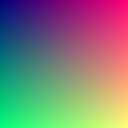

In [9]:
import numpy as np
from PIL import Image
from IPython.display import display

# 生成一张 128×128 的 RGB 测试图像
test_image = np.zeros((128, 128, 3), dtype=np.uint8)

test_image[:, :, 0] = np.linspace(
    0, 255, 128, dtype=np.uint8
)[None, :]

test_image[:, :, 1] = np.linspace(
    0, 255, 128, dtype=np.uint8
)[:, None]

test_image[:, :, 2] = 120

# 保存测试输入
input_path = "/content/test_input.png"
save_path = "/content/test_output.png"

Image.fromarray(test_image).save(input_path)

# 使用我们自己的模块读取
image = load_image(input_path)

print("图像尺寸:", image.shape)
print("图像数据类型:", image.dtype)

# 使用我们自己的模块保存
save_image(image, save_path)

# 再次读取，检查保存结果
result = load_image(save_path)

print("保存后尺寸:", result.shape)
print("保存后数据类型:", result.dtype)

assert np.array_equal(image, result)

print("图像读取与保存测试全部通过！")

display(Image.open(save_path))

In [10]:
import subprocess

repo_dir = "/content/OpenUIE-Benchmark"

subprocess.run(
    ["git", "-C", repo_dir, "pull", "origin", "main"],
    check=True
)

print("项目代码更新成功！")

项目代码更新成功！


In [11]:
import sys

src_path = "/content/OpenUIE-Benchmark/src"

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from open_uie.models.base import BaseEnhancementModel

print("BaseEnhancementModel 导入成功！")

BaseEnhancementModel 导入成功！


In [12]:
import numpy as np

class TestEnhancementModel(BaseEnhancementModel):

    def __init__(self):
        super().__init__(model_name="TestModel")

    def predict(self, image):
        # 暂时不改变图像，只复制并返回
        return image.copy()


# 创建测试模型
model = TestEnhancementModel()

# 生成一张 128×128 的 RGB 测试图像
test_image = np.random.randint(
    0, 256,
    size=(128, 128, 3),
    dtype=np.uint8
)

# 调用模型
enhanced_image = model(test_image)

print("模型名称:", model)
print("输入尺寸:", test_image.shape)
print("输出尺寸:", enhanced_image.shape)
print("输出类型:", enhanced_image.dtype)

assert enhanced_image.shape == test_image.shape
assert enhanced_image.dtype == np.uint8
assert np.array_equal(enhanced_image, test_image)

print("统一模型接口测试全部通过！")

模型名称: TestEnhancementModel(name='TestModel')
输入尺寸: (128, 128, 3)
输出尺寸: (128, 128, 3)
输出类型: uint8
统一模型接口测试全部通过！
